# Breast Cancer Classification — CA-4

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             RocCurveDisplay, ConfusionMatrixDisplay)

## 2. Dataset

In [2]:
dataset = load_breast_cancer(as_frame=True)
X = dataset.data.copy()
y = pd.Series((dataset.target == 0).astype(int), name='malignant')
print('Shape:', X.shape)
print('Benign:', (y == 0).sum(), '| Malignant:', (y == 1).sum())
display(X.head())

Shape: (569, 30)
Benign: 357 | Malignant: 212


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 3. EDA

In [3]:
print('Missing values:', int(X.isna().sum().sum()))
print('Duplicate rows:', int(X.duplicated().sum()))
display(X.describe().T)

Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


In [4]:
q1, q3 = X.quantile(.25), X.quantile(.75)
iqr = q3 - q1
outliers = X.lt(q1 - 1.5 * iqr) | X.gt(q3 + 1.5 * iqr)
print('IQR-flagged cells:', int(outliers.sum().sum()))
display(outliers.sum().sort_values(ascending=False).head(10))

IQR-flagged cells: 608


area error                 65
radius error               38
perimeter error            38
worst area                 35
smoothness error           30
fractal dimension error    28
compactness error          28
symmetry error             27
mean area                  25
worst fractal dimension    24
dtype: int64

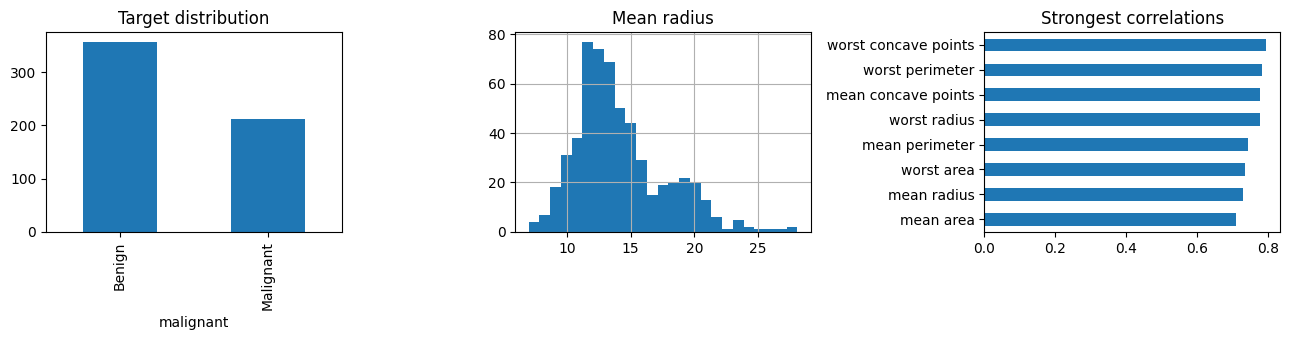

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
y.map({0: 'Benign', 1: 'Malignant'}).value_counts().plot.bar(ax=ax[0])
X['mean radius'].hist(bins=25, ax=ax[1])
X.join(y).corr()['malignant'].drop('malignant').abs().sort_values().tail(8).plot.barh(ax=ax[2])
ax[0].set_title('Target distribution')
ax[1].set_title('Mean radius')
ax[2].set_title('Strongest correlations')
plt.tight_layout()
plt.show()

## 4. Train–Test Split

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('Training:', len(X_train), '| Testing:', len(X_test))

Training: 398 | Testing: 171


## 5. Models

In [7]:
def make_pipeline(model, scale=False):
    steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scaler', StandardScaler()))
    return Pipeline(steps + [('model', model)])

In [8]:
models = {
    'Logistic Regression': make_pipeline(
        LogisticRegression(max_iter=3000, class_weight='balanced', random_state=42), True
    ),
    'Decision Tree': make_pipeline(
        DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42)
    ),
    'KNN': make_pipeline(KNeighborsClassifier(n_neighbors=5), True),
    'Random Forest': make_pipeline(
        RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1)
    ),
    'Gradient Boosting': make_pipeline(GradientBoostingClassifier(random_state=42))
}

## 6. Model Comparison

In [9]:
records = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    records.append({
        'model': name,
        'accuracy': accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall': recall_score(y_test, pred),
        'f1': f1_score(y_test, pred),
        'auc': roc_auc_score(y_test, prob),
        'cv_f1': cross_val_score(model, X_train, y_train, cv=cv, scoring='f1', n_jobs=-1).mean()
    })

In [10]:
comparison = pd.DataFrame(records).set_index('model')
display(comparison.round(4))

,accuracy,precision,recall,f1,auc,cv_f1
model,,,,,,
Logistic Regression,0.9766,0.9839,0.9531,0.9683,0.9969,0.9572
Decision Tree,0.9123,0.9016,0.8594,0.8800,0.8978,0.9004
KNN,0.9649,1.0000,0.9062,0.9508,0.9882,0.9425
Random Forest,0.9708,1.0000,0.9219,0.9593,0.9966,0.9220
Gradient Boosting,0.9649,1.0000,0.9062,0.9508,0.9971,0.9116


## 7. Random Forest Tuning

In [11]:
param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 6, 12],
    'model__min_samples_leaf': [1, 3]
}
search = GridSearchCV(
    make_pipeline(RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1)),
    param_grid, scoring='f1', cv=cv, n_jobs=-1
)
search.fit(X_train, y_train)
final_model = search.best_estimator_
print('Best parameters:', search.best_params_)
print('Cross-validation F1:', round(search.best_score_, 4))

Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 3, 'model__n_estimators': 100}
Cross-validation F1: 0.9267


In [12]:
rf_pred = final_model.predict(X_test)
rf_prob = final_model.predict_proba(X_test)[:, 1]
rf_results = {
    'accuracy': accuracy_score(y_test, rf_pred),
    'precision': precision_score(y_test, rf_pred),
    'recall': recall_score(y_test, rf_pred),
    'f1': f1_score(y_test, rf_pred),
    'auc': roc_auc_score(y_test, rf_prob)
}
display(pd.Series(rf_results, name='Tuned Random Forest').round(4))

accuracy     0.9766
precision    1.0000
recall       0.9375
f1           0.9677
auc          0.9980
Name: Tuned Random Forest, dtype: float64

## 8. ROC and Confusion Matrix

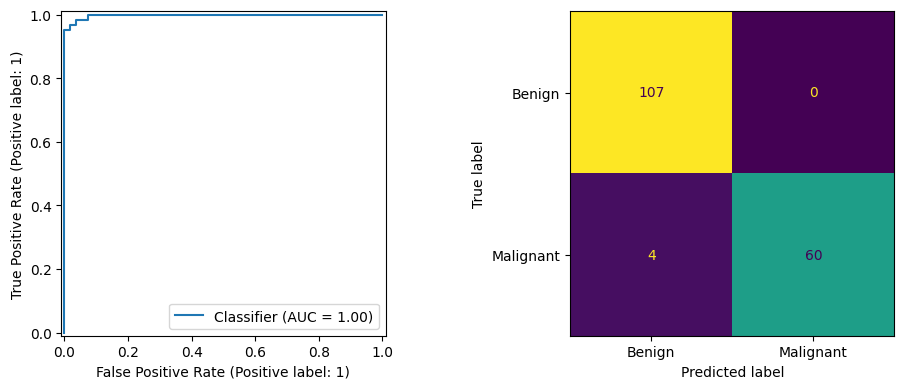

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
RocCurveDisplay.from_predictions(y_test, rf_prob, ax=ax[0])
ConfusionMatrixDisplay.from_predictions(
    y_test, rf_pred, display_labels=['Benign', 'Malignant'], ax=ax[1], colorbar=False
)
plt.tight_layout()
plt.show()

## 9. Feature Importance

In [14]:
importance = pd.Series(
    final_model.named_steps['model'].feature_importances_, index=X.columns
).sort_values(ascending=False)
display(importance.head(10).to_frame('importance'))

,importance
worst area,0.172998
mean concave points,0.119631
worst concave points,0.097872
worst perimeter,0.083568
mean perimeter,0.074062
mean concavity,0.073548
worst radius,0.071565
mean radius,0.062024
mean area,0.041820
worst concavity,0.030547


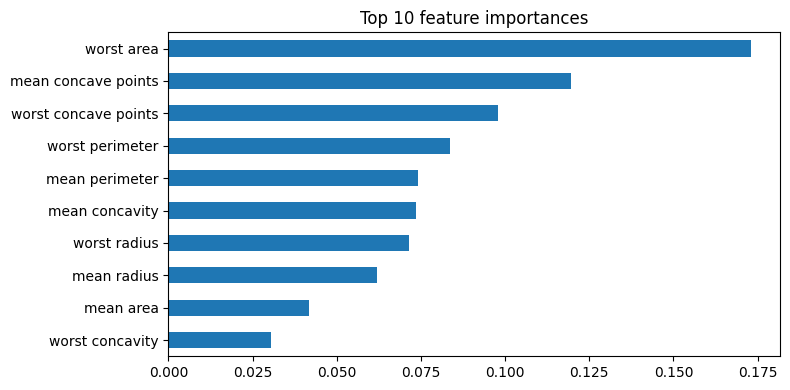

In [15]:
importance.head(10).iloc[::-1].plot.barh(figsize=(8, 4), title='Top 10 feature importances')
plt.tight_layout()
plt.show()

## 10. Final Evaluation

In [16]:
selected = models['Logistic Regression']
selected_pred = selected.predict(X_test)
selected_prob = selected.predict_proba(X_test)[:, 1]
print(classification_report(y_test, selected_pred, target_names=['Benign', 'Malignant']))
print('Logistic Regression confusion matrix:')
print(confusion_matrix(y_test, selected_pred))

              precision    recall  f1-score   support

      Benign       0.97      0.99      0.98       107
   Malignant       0.98      0.95      0.97        64

    accuracy                           0.98       171
   macro avg       0.98      0.97      0.97       171
weighted avg       0.98      0.98      0.98       171

Logistic Regression confusion matrix:
[[106   1]
 [  3  61]]


In [17]:
print('Logistic Regression F1:', round(f1_score(y_test, selected_pred), 4))
print('Logistic Regression ROC AUC:', round(roc_auc_score(y_test, selected_prob), 4))
print('Tuned Random Forest F1:', round(f1_score(y_test, rf_pred), 4))
print('Tuned Random Forest ROC AUC:', round(roc_auc_score(y_test, rf_prob), 4))

Logistic Regression F1: 0.9683
Logistic Regression ROC AUC: 0.9969
Tuned Random Forest F1: 0.9677
Tuned Random Forest ROC AUC: 0.998
